# Iris Flower Classification – Machine Learning Internship

**Algorithms:** Logistic Regression and Decision Tree  
**Dataset:** Iris (150 rows, 4 numerical features, 3 species)  
**Objective:** Train and compare two supervised classification models.

Run the notebook from the same folder as `iris.csv`. The notebook uses a stratified 80/20 train-test split and fits scaling only on the training data to prevent data leakage.


## 1. Import the required libraries

If any library is missing, install the dependencies in the VS Code terminal using:

```bash
python -m pip install pandas numpy matplotlib seaborn scikit-learn jupyter ipykernel
```


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Consistent plot appearance
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load the dataset

Keep `iris.csv` in the same folder as this notebook. The CSV contains the four flower measurements and the target species.


In [2]:
df = pd.read_csv("iris.csv")

print("First five rows:")
display(df.head())

print("\\nDataset shape:", df.shape)
print("\\nColumn names:", df.columns.tolist())


First five rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


\nDataset shape: (150, 5)
\nColumn names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


## 3. Explore and understand the data

In [3]:
print("Dataset information:")
df.info()

print("\\nStatistical summary:")
display(df.describe())

print("\\nMissing values in each column:")
display(df.isnull().sum())

print("\\nNumber of samples in each species:")
display(df["species"].value_counts())


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB
\nStatistical summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


\nMissing values in each column:


sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

\nNumber of samples in each species:


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

## 4. Exploratory Data Analysis – Pairplot

A pairplot displays pairwise relationships between numerical features. The hue parameter colors observations by species, helping us see which classes are easier to separate.


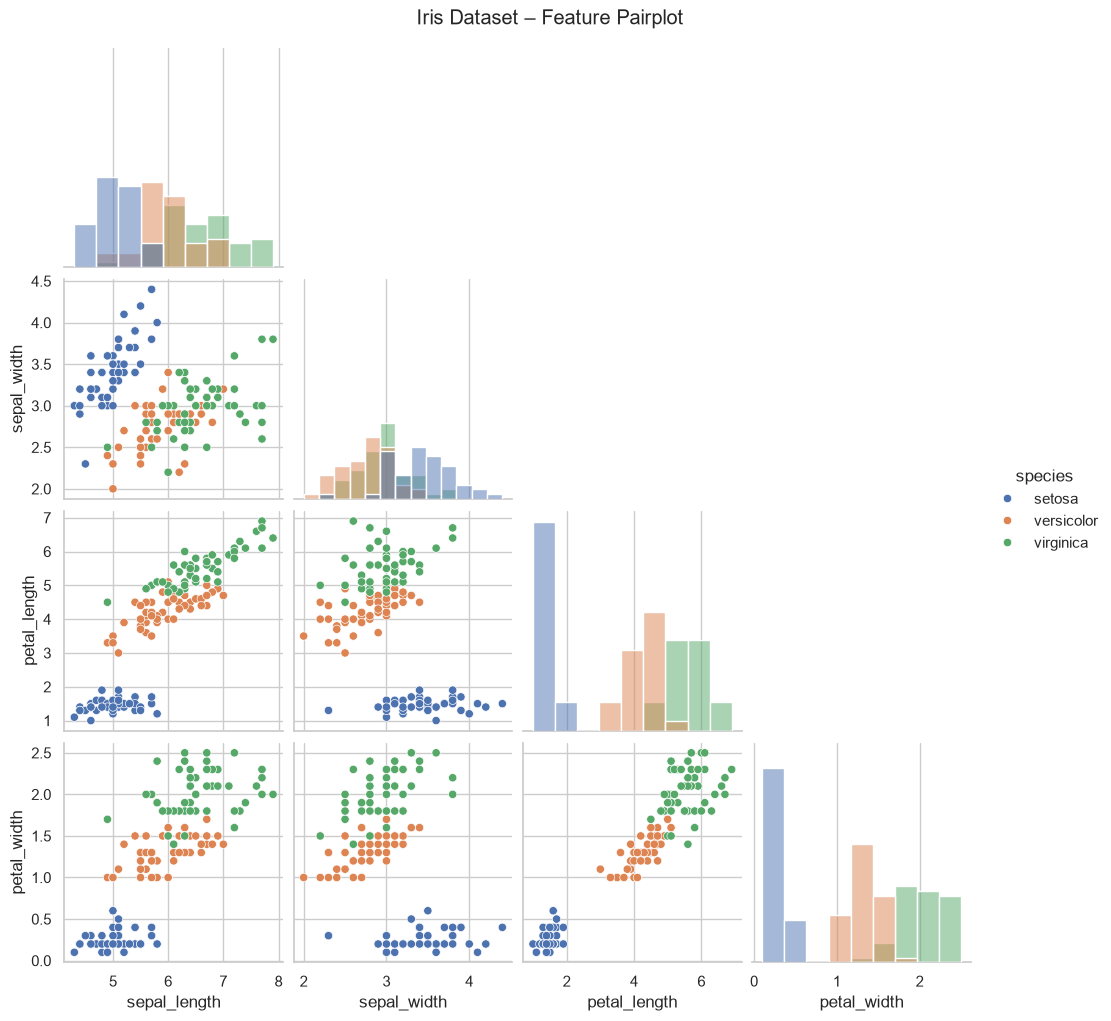

In [4]:
sns.pairplot(df, hue="species", diag_kind="hist", corner=True)
plt.suptitle("Iris Dataset – Feature Pairplot", y=1.02)
plt.show()


## 5. Separate input features and target

The four measurement columns are the independent variables (`X`). The `species` column is the target (`y`) that the models will predict.


In [5]:
X = df.drop(columns=["species"])
y = df["species"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Features:", X.columns.tolist())
print("Classes:", sorted(y.unique()))


Feature shape: (150, 4)
Target shape: (150,)
Features: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Classes: ['setosa', 'versicolor', 'virginica']


## 6. Split the dataset into training and testing sets (80/20)

`test_size=0.20` reserves 20% of the rows for testing. `stratify=y` preserves the class proportions in both sets. `random_state=42` makes the split reproducible.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\\nTraining class distribution:")
print(y_train.value_counts())
print("\\nTesting class distribution:")
print(y_test.value_counts())


Training samples: 120
Testing samples: 30
\nTraining class distribution:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64
\nTesting class distribution:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


## 7. Build and train the machine learning models

Both models are placed in Scikit-learn pipelines. `StandardScaler` learns the feature means and standard deviations from the training set only, then applies that transformation to the test set. Scaling is important for Logistic Regression. Decision Trees generally do not require scaling, but it is included here to meet the project requirement and keep preprocessing consistent.

The Decision Tree uses a fixed `random_state` so its results are reproducible.


In [7]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Decision Tree": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ])
}

predictions = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    predictions[model_name] = model.predict(X_test)
    print(f"{model_name} trained successfully.")


Logistic Regression trained successfully.
Decision Tree trained successfully.


## 8. Evaluate model performance

For this three-class classification problem, the notebook reports **macro-average** precision, recall and F1-score. Macro averaging calculates the metric independently for each class and then gives each class equal weight. The full classification report also includes per-class and weighted-average results.


In [8]:
results = []

for model_name, y_pred in predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (Macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (Macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))


,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


## 9. Detailed classification reports

In [9]:
for model_name, y_pred in predictions.items():
    print("=" * 65)
    print(model_name)
    print("=" * 65)
    print(classification_report(y_test, y_pred, digits=4, zero_division=0))


Logistic Regression
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30

Decision Tree
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



## 10. Confusion matrix heatmaps

A confusion matrix compares actual classes (rows) with predicted classes (columns). Correct predictions appear on the main diagonal. Off-diagonal values represent misclassifications.


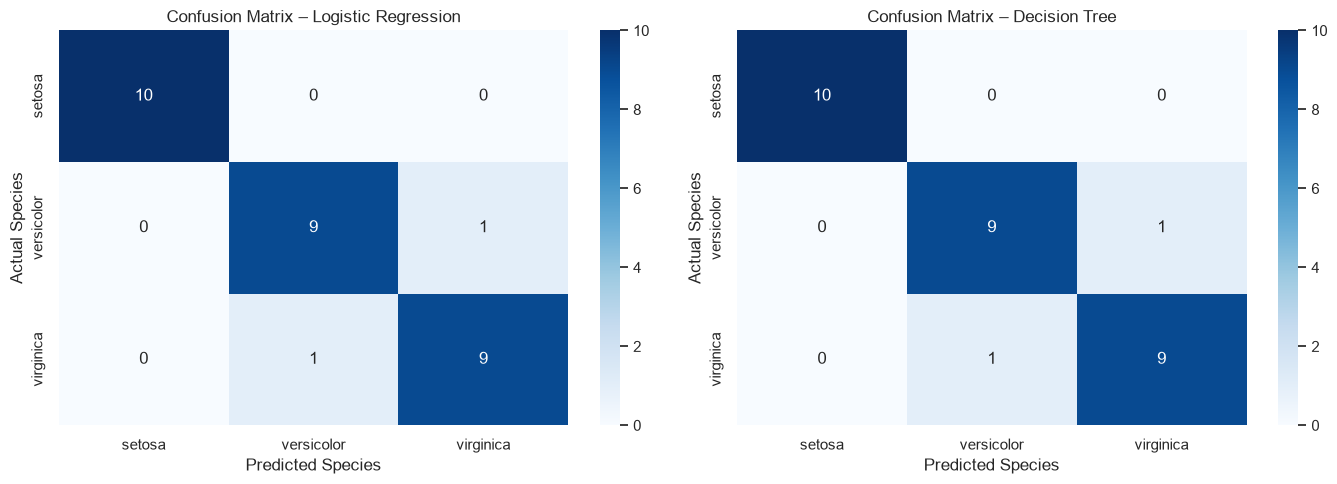

In [10]:
class_names = sorted(y.unique())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_names)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )
    ax.set_title(f"Confusion Matrix – {model_name}")
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()


## 11. Decision boundary visualization

A decision boundary is a 2D visualization showing which class a model predicts in different regions of a feature space.

**Important:** The main evaluation above uses all four features. A 2D decision boundary cannot directly display a four-dimensional feature space, so this section trains separate visualization-only models using `petal_length` and `petal_width`. Their scores should not be confused with the four-feature benchmark scores.


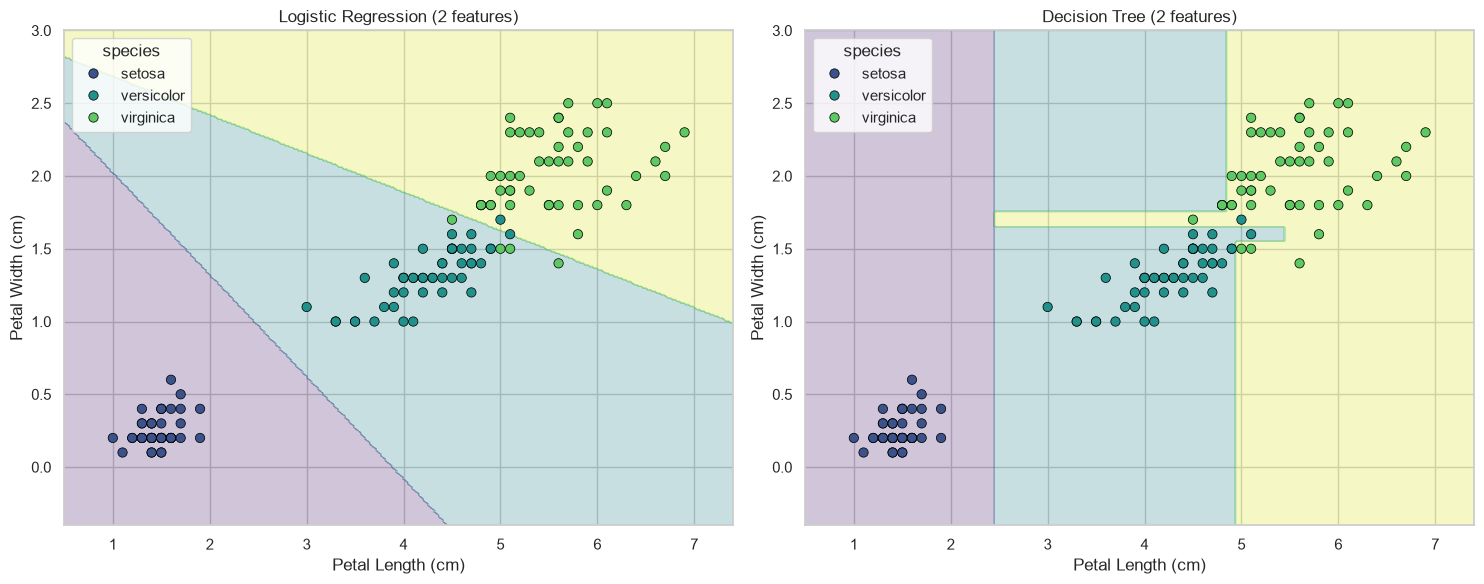

In [11]:
# Use two features so that predictions can be plotted on a 2D graph.
boundary_features = ["petal_length", "petal_width"]

X_2d = df[boundary_features]
X_2d_train, X_2d_test, y_2d_train, y_2d_test = train_test_split(
    X_2d,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

boundary_models = {
    "Logistic Regression (2 features)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Decision Tree (2 features)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ])
}

for model in boundary_models.values():
    model.fit(X_2d_train, y_2d_train)

# Create a grid covering the feature ranges.
x_min, x_max = X_2d[boundary_features[0]].min() - 0.5, X_2d[boundary_features[0]].max() + 0.5
y_min, y_max = X_2d[boundary_features[1]].min() - 0.5, X_2d[boundary_features[1]].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=boundary_features
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (model_name, model) in zip(axes, boundary_models.items()):
    grid_predictions = model.predict(grid)
    class_to_number = {name: i for i, name in enumerate(class_names)}
    Z = np.array([class_to_number[label] for label in grid_predictions]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
    sns.scatterplot(
        data=df,
        x=boundary_features[0],
        y=boundary_features[1],
        hue="species",
        palette="viridis",
        edgecolor="black",
        s=45,
        ax=ax,
        legend=True
    )
    ax.set_title(model_name)
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")

plt.tight_layout()
plt.show()


## 12. Compare the models

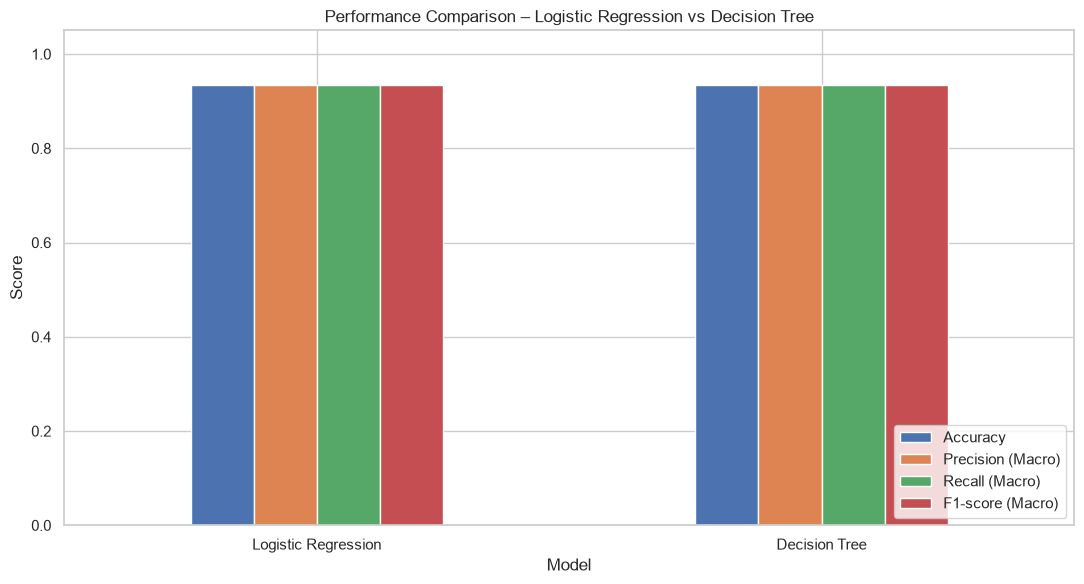

Model with the highest macro F1-score: Logistic Regression


In [12]:
metrics_to_plot = results_df[[
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-score (Macro)"
]]

ax = metrics_to_plot.plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))
ax.set_title("Performance Comparison – Logistic Regression vs Decision Tree")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.tick_params(axis="x", rotation=0)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_model_name = results_df["F1-score (Macro)"].idxmax()
print("Model with the highest macro F1-score:", best_model_name)


## 13. Final conclusion

The notebook compares Logistic Regression and Decision Tree using the same training and testing split. Use the metric table and classification reports to identify how well each model predicts the three Iris species.

Do not assume one algorithm is always better. The better model for this experiment is the one supported by the evaluation results. Because the Iris dataset is small and relatively easy to classify, high scores are expected; they do not prove that the model will perform equally well on unrelated real-world datasets.

## 14. Save the trained models (optional)

This section saves the fitted pipelines, including their scaler and classifier, so they can be reused later.


In [13]:
import joblib

joblib.dump(models["Logistic Regression"], "logistic_regression_iris.joblib")
joblib.dump(models["Decision Tree"], "decision_tree_iris.joblib")

print("Both trained pipelines have been saved.")


Both trained pipelines have been saved.


In [14]:
# Test a new flower sample

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

for model_name, model in models.items():
    prediction = model.predict(new_flower)

    print(f"{model_name}: {prediction[0]}")

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(new_flower)[0]
        print("Prediction probabilities:")
        for species, probability in zip(model.classes_, probabilities):
            print(f"{species}: {probability:.2%}")

    print("-" * 40)

Logistic Regression: setosa
Prediction probabilities:
setosa: 98.08%
versicolor: 1.92%
virginica: 0.00%
----------------------------------------
Decision Tree: setosa
Prediction probabilities:
setosa: 100.00%
versicolor: 0.00%
virginica: 0.00%
----------------------------------------


In [15]:
# Test three different flower samples

test_flowers = pd.DataFrame([
    [5.1, 3.5, 1.4, 0.2],  # Setosa
    [6.4, 3.2, 4.5, 1.5],  # Versicolor
    [6.3, 3.3, 6.0, 2.5]   # Virginica
], columns=X.columns)

for index, flower in test_flowers.iterrows():

    sample = pd.DataFrame([flower])

    print(f"\nFlower Sample {index + 1}")

    for model_name, model in models.items():

        prediction = model.predict(sample)[0]
        probabilities = model.predict_proba(sample)[0]

        print(f"\n{model_name}")
        print(f"Predicted Species: {prediction}")

        for species, probability in zip(
            model.classes_, probabilities
        ):
            print(f"{species}: {probability:.2%}")


Flower Sample 1

Logistic Regression
Predicted Species: setosa
setosa: 98.08%
versicolor: 1.92%
virginica: 0.00%

Decision Tree
Predicted Species: setosa
setosa: 100.00%
versicolor: 0.00%
virginica: 0.00%

Flower Sample 2

Logistic Regression
Predicted Species: versicolor
setosa: 1.71%
versicolor: 78.94%
virginica: 19.35%

Decision Tree
Predicted Species: versicolor
setosa: 0.00%
versicolor: 100.00%
virginica: 0.00%

Flower Sample 3

Logistic Regression
Predicted Species: virginica
setosa: 0.00%
versicolor: 0.86%
virginica: 99.14%

Decision Tree
Predicted Species: virginica
setosa: 0.00%
versicolor: 0.00%
virginica: 100.00%
